In [1]:
import geopandas as gpd
import pandas as pd
import fiona
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
from shapely.geometry import LineString

## Lê e carrega o conteúdo dos arquivos

### Carrega os dataframes:

- Setores da cidade (`setores`)
- Favelas (`favelas`)
- indicadores da rua (`df_entorno`)

In [ ]:
path_gpkg="./data/ibge_census_data_2022/niteroi_census_borders.gpkg"
setores = gpd.read_file(path_gpkg, layer="setores_censitarios_2022_ssagi")

favelas = gpd.read_file(path_gpkg, layer="favelas_e_comunidades_censo2022")

df_entorno=pd.read_csv("./data/ibge_census_data_2022/census_tracts_indicators/block_face_environment_indicators_pct.csv", sep=";")

### Carrega e trata os dados do GTFS:

- Trajetos (`mapa_linhas_onibus`)
- Paradas (`stops_df`)

In [ ]:
agencias=["TransNit_20260320"]
mapas = []
stops_parciais = []

for ag in agencias:
    base_dir="./data/GTFS_data/"+ag

    #Importa arquivos
    routes=pd.read_csv(base_dir+"/routes.txt", sep=",")
    shapes=pd.read_csv(base_dir+"/shapes.txt", sep=",")
    trips =pd.read_csv(base_dir+"/trips.txt",  sep=",")
    stops =pd.read_csv(base_dir+"/stops.txt",  sep=",")

    #Limpeza dos dados
    #Pega cada linha só uma vez
    trips_reduced=trips.drop_duplicates(subset=['route_id', 'shape_id'])

    #ordena a ordem dos pontos de uma mesma linha
    shapes = shapes.sort_values(by=['shape_id', 'shape_pt_sequence'])
    
    linhas = shapes.groupby('shape_id').apply(
        lambda x: LineString(zip(x['shape_pt_lon'], x['shape_pt_lat']))
        ).reset_index(name='geometry')
    
    gdf_shapes = gpd.GeoDataFrame(linhas, geometry='geometry', crs="EPSG:4326")

    #faz o merging
    df_rotas_trips = routes.merge(trips_reduced, on='route_id', how='inner')
    submap = gdf_shapes.merge(df_rotas_trips, on='shape_id', how='inner')
    mapas.append(submap)
    stops_parciais.append(stops)

#### faz o merging e cria as Databases finais

In [4]:
#linhas de onibus
mapa_linhas_onibus = pd.concat(mapas, ignore_index=True)

#stops
stops = pd.concat(stops_parciais, ignore_index=True).drop_duplicates(subset=['stop_id'])

stops_df = gpd.GeoDataFrame(
    stops, 
    geometry=gpd.points_from_xy(stops.stop_lon, stops.stop_lat), 
    crs="EPSG:4326"
)
stops_df=stops_df.to_crs("EPSG:4674")

#### Corrige pontos registrados errado no mapa

In [5]:
stops=stops_df
stops_df=gpd.clip(stops_df, setores)

### Pequena exibição dos Data Frames

In [ ]:
df_entorno.head()

In [7]:
setores.value_counts("NM_REG_PLAN")

NM_REG_PLAN
Praias da Baía    467
Região Norte      406
Região Oceânic    199
Pendotiba         152
Não classifica     43
Região Leste       22
Name: count, dtype: int64

In [ ]:
mapa_linhas_onibus.head()

In [ ]:
stops_df.head()

## Faz o merge dos dois dataframes:

Iguala as colunas com o código dos setores (mesmo tipo) e une os dois dataframes:
- **setores:** zonas/bairros de niterói
- **df_entorno:** informações relevantes sobre a infraestrutura de cada zona, como obstáculos na calçada, existência de rampas e bueiros

In [10]:
setores['CD_SETOR'] = setores['CD_SETOR'].astype(str)
df_entorno['cd_setor'] = df_entorno['cd_setor'].astype(str)
mapa_infraestrutura=setores.merge(df_entorno, left_on='CD_SETOR', right_on='cd_setor', how='inner')

### Exibição de dados do data Frame combinado

In [ ]:
mapa_infraestrutura.head()

In [ ]:
mapa_infraestrutura.info()

## Trata colunas e cria índice combinado

Altera os tipos das colunas `bueiro_nao_perc` e `pavimentacao_nao_perc` para torná-los números em ponto flutuante (ao invés de strings) e poder utilizá-los para operações e para gerar um mapa de calor das regiões com menor infraestrutura, ou seja, em que o valor dessas variáveis é maior

In [13]:
mapa_infraestrutura['bueiro_nao_perc']= mapa_infraestrutura['bueiro_nao_perc'].astype(str).str.replace(',', '.').astype(float)
mapa_infraestrutura['pavimentacao_nao_perc']= mapa_infraestrutura['pavimentacao_nao_perc'].astype(str).str.replace(',', '.').astype(float)

In [14]:
mapa_infraestrutura['indicador_infra']= (mapa_infraestrutura['bueiro_nao_perc']+mapa_infraestrutura['pavimentacao_nao_perc'])/2

## Plots iniciais

### Gera o mapa de calor baseado na falta de bueiros


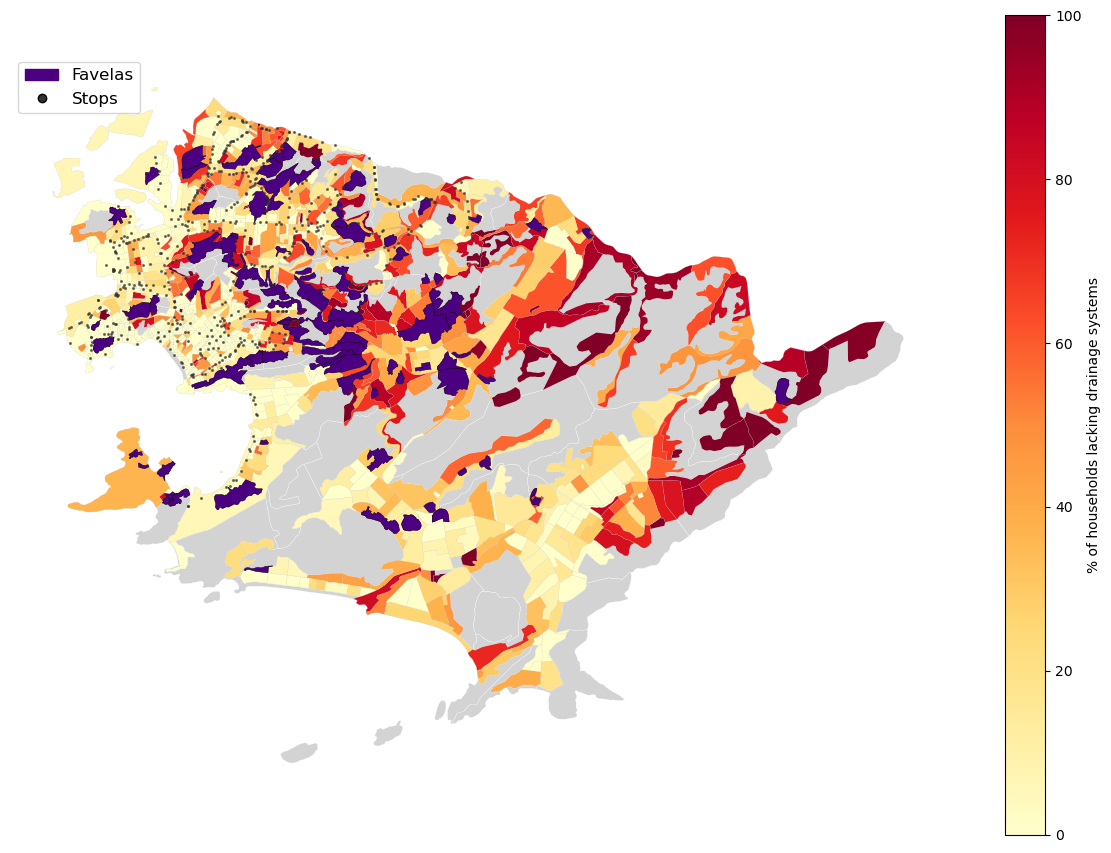

In [15]:
fig, ax = plt.subplots(1, 1, figsize=(12, 12))

setores.plot(ax=ax, color='lightgray', edgecolor='white', linewidth=0.2)

mapa_infraestrutura.plot(
    column='bueiro_nao_perc', 
    cmap='YlOrRd',
    linewidth=0.1,
    ax=ax,
    edgecolor='0.8',
    legend=True,
    legend_kwds={'label': "% of households lacking drainage systems", 'orientation': "vertical", 'shrink': 0.7}
)
ax.set_axis_off()

favelas.plot(ax=ax, color='indigo', edgecolor='black', linewidth=0.3)

stops_df.plot(ax=ax, color='#333333', markersize=1.5, alpha=0.6)

legenda_favela = mpatches.Patch(color='indigo', label='Favelas')
legenda_stops  = mlines.Line2D([], [], color='none', marker='o', markerfacecolor='#333333', markersize=6, label='Stops')
ax.legend(handles=[legenda_favela, legenda_stops], loc='upper left', fontsize=12)
plt.tight_layout()

### Gera o mapa de calor baseado na falta de pavimentação


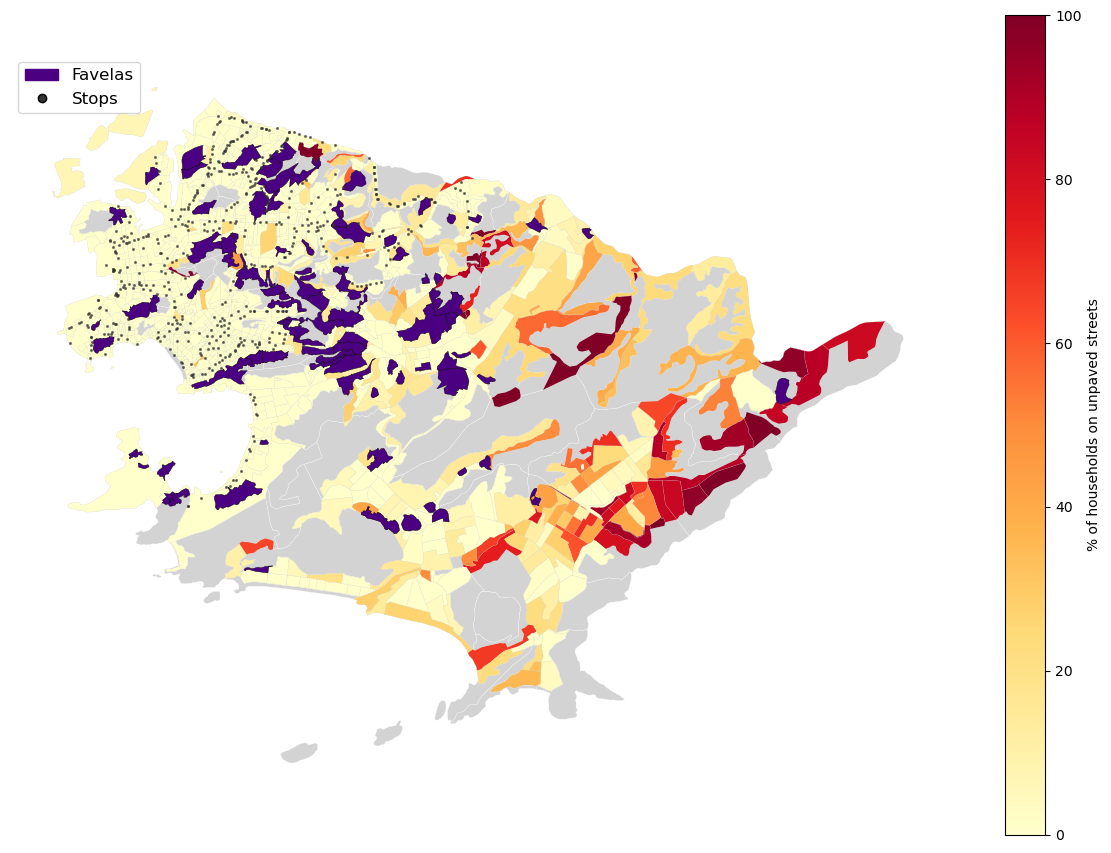

In [16]:
fig, ax = plt.subplots(1, 1, figsize=(12, 12))

setores.plot(ax=ax, color='lightgray', edgecolor='white', linewidth=0.2)

mapa_infraestrutura.plot(
    column='pavimentacao_nao_perc', 
    cmap='YlOrRd',
    linewidth=0.1,
    ax=ax,
    edgecolor='0.8',
    legend=True,
    legend_kwds={'label': "% of households on unpaved streets", 'orientation': "vertical", 'shrink': 0.7}
)
ax.set_axis_off()

favelas.plot(ax=ax, color='indigo', edgecolor='black', linewidth=0.3)

stops_df.plot(ax=ax, color='#333333', markersize=1.5, alpha=0.6)

legenda_favela = mpatches.Patch(color='indigo', label='Favelas')
legenda_stops  = mlines.Line2D([], [], color='none', marker='o', markerfacecolor='#333333', markersize=6, label='Stops')
ax.legend(handles=[legenda_favela, legenda_stops], loc='upper left', fontsize=12)
plt.tight_layout()

### Gera o mapa de calor baseado no índice combinado

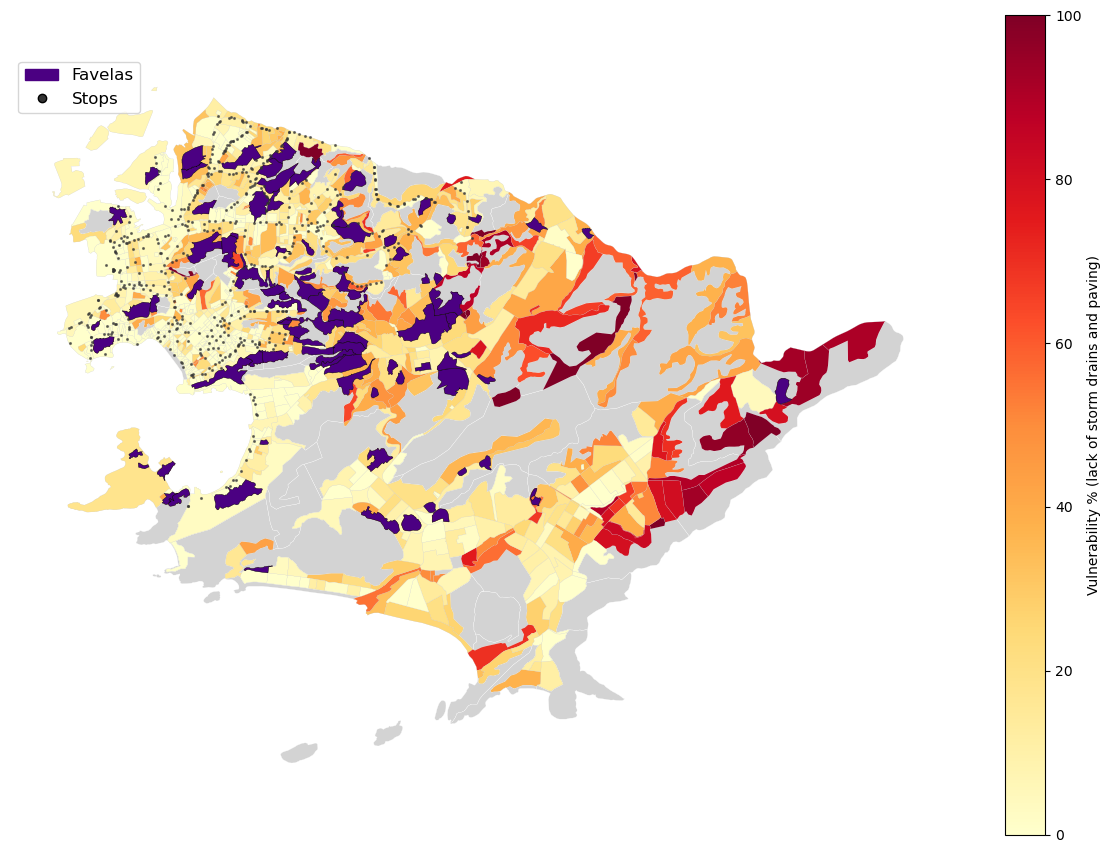

In [17]:
fig, ax = plt.subplots(1, 1, figsize=(12, 12))

setores.plot(ax=ax, color='lightgray', edgecolor='white', linewidth=0.2)

mapa_infraestrutura.plot(
    column='indicador_infra', 
    cmap='YlOrRd',
    linewidth=0.1,
    ax=ax,
    edgecolor='0.8',
    legend=True,
    legend_kwds={'label': "Vulnerability % (lack of storm drains and paving)", 'orientation': "vertical", 'shrink': 0.7}
)
ax.set_axis_off()

favelas.plot(ax=ax, color='indigo', edgecolor='black', linewidth=0.3)

stops_df.plot(ax=ax, color='#333333', markersize=1.5, alpha=0.6)

legenda_favela = mpatches.Patch(color='indigo', label='Favelas')
legenda_stops  = mlines.Line2D([], [], color='none', marker='o', markerfacecolor='#333333', markersize=6, label='Stops')
ax.legend(handles=[legenda_favela, legenda_stops], loc='upper left', fontsize=12)
plt.tight_layout()

### Analisa as linhas quanto a chuva

Usa os dados do outro notebook pra gerar um mapa das rotas mais críticas

#### Linhas críticas quanto ao tempo

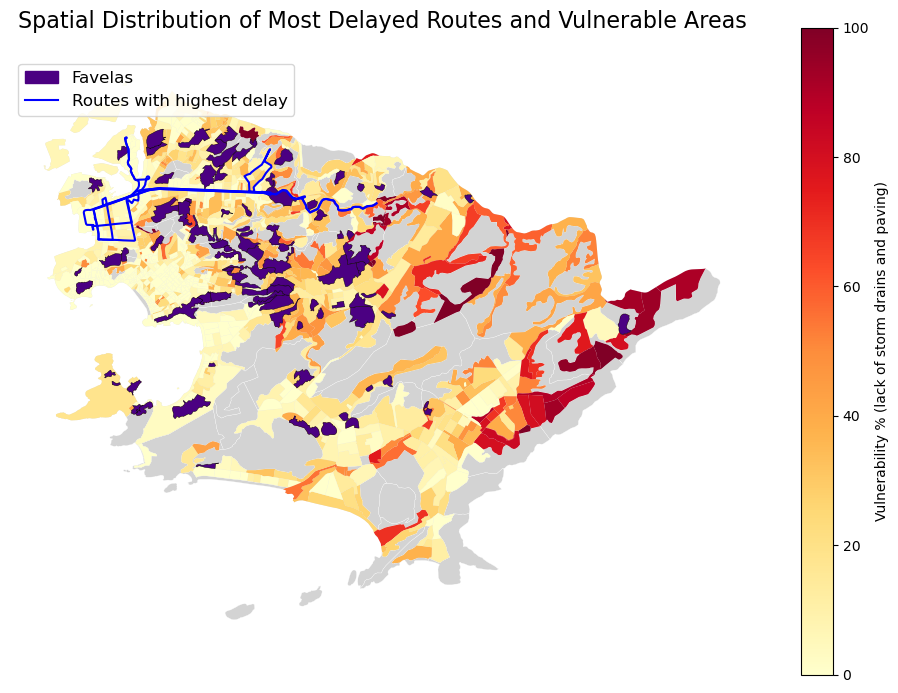

In [ ]:
# +10min atraso em media
linhas_mais_afetadas = ['22','32','23','6','15','35','26','16','34'] 

rotas_criticas = mapa_linhas_onibus[mapa_linhas_onibus['route_short_name'].isin(linhas_mais_afetadas)]
fig, ax = plt.subplots(1, 1, figsize=(12, 12))
setores.plot(ax=ax, color='lightgray', edgecolor='white', linewidth=0.2)

mapa_infraestrutura.plot(
    column='indicador_infra', 
    cmap='YlOrRd',
    linewidth=0,
    ax=ax,
    legend=True,
    legend_kwds={'label': "Vulnerability % (lack of storm drains and paving)", 'orientation': "vertical", 'shrink': 0.7}
)

favelas.plot(ax=ax, color='indigo', edgecolor='black', linewidth=0.3)

rotas_criticas.plot(ax=ax, color='blue', linewidth=1.5, zorder=5)

ax.set_axis_off()
ax.set_title("Spatial Distribution of Most Delayed Routes and Vulnerable Areas", fontsize=16, pad=20)

legenda_favela = mpatches.Patch(color='indigo', label='Favelas')
legenda_rota = mlines.Line2D([], [], color='blue', linewidth=1.5, label='Routes with highest delay')
ax.legend(handles=[legenda_favela, legenda_rota], loc='upper left', fontsize=12)

plt.show()

#### Linhas críticas quanto à velocidade

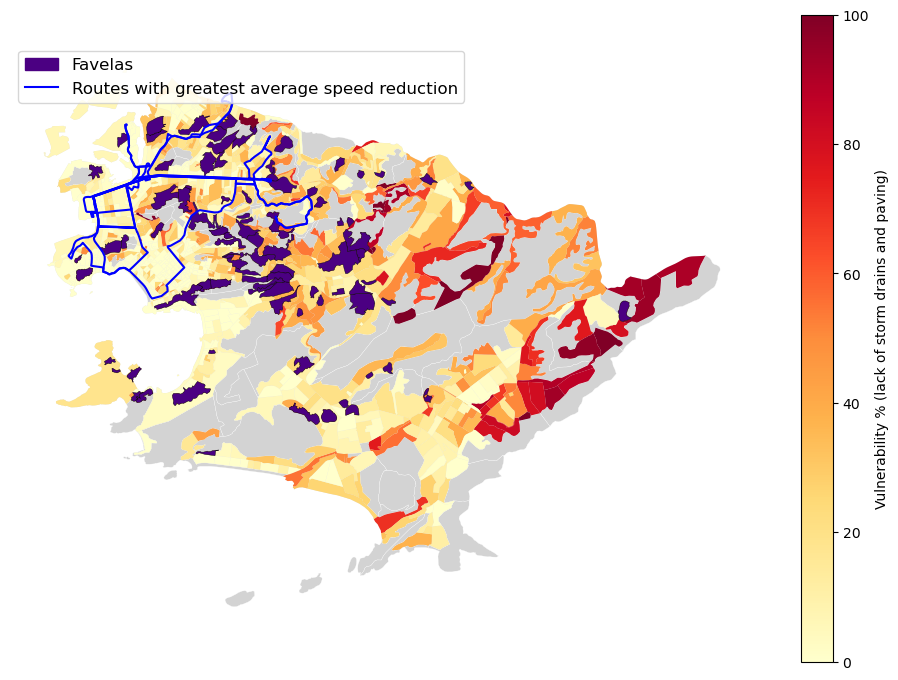

In [ ]:
# redução de pelo menos 2 km/h em dias de chuva 
linhas_mais_afetadas = ['55A', '60', '26A', '41BC', '22', '49.2']

rotas_criticas = mapa_linhas_onibus[mapa_linhas_onibus['route_short_name'].isin(linhas_mais_afetadas)]
fig, ax = plt.subplots(1, 1, figsize=(12, 12))
setores.plot(ax=ax, color='lightgray', edgecolor='white', linewidth=0.2)

mapa_infraestrutura.plot(
    column='indicador_infra', 
    cmap='YlOrRd',
    linewidth=0,
    ax=ax,
    legend=True,
    legend_kwds={'label': "Vulnerability % (lack of storm drains and paving)", 'orientation': "vertical", 'shrink': 0.7}
)

favelas.plot(ax=ax, color='indigo', edgecolor='black', linewidth=0.3)

rotas_criticas.plot(ax=ax, color='blue', linewidth=1.5, zorder=5)

ax.set_axis_off()

legenda_favela = mpatches.Patch(color='indigo', label='Favelas')
legenda_rota = mlines.Line2D([], [], color='blue', linewidth=1.5, label='Routes with greatest average speed reduction')
ax.legend(handles=[legenda_favela, legenda_rota], loc='upper left', fontsize=12)

plt.show()

### Plota todas as linhas de ônibus sobre o mapa

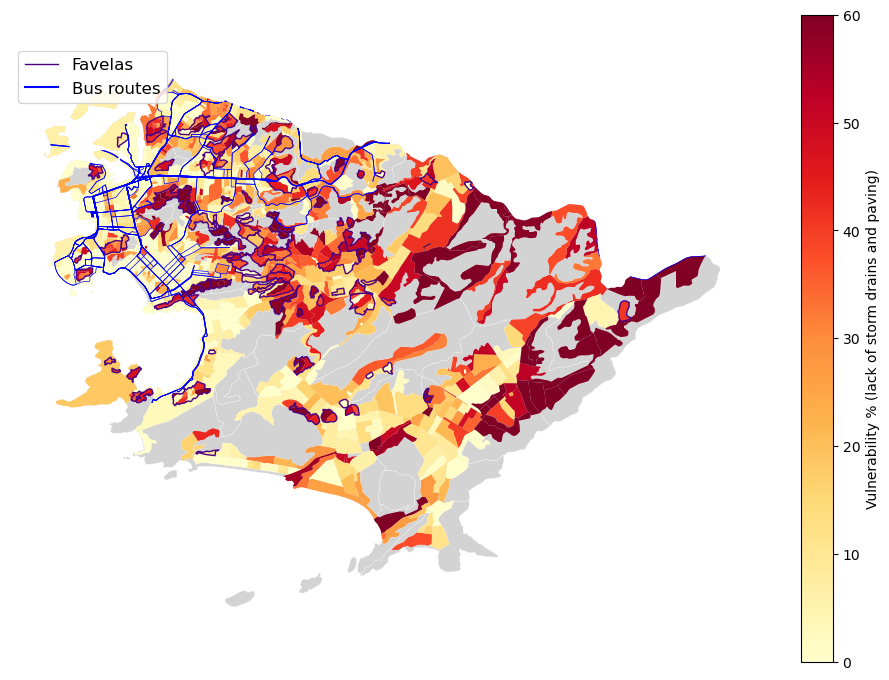

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(12, 12))
setores.plot(ax=ax, color='lightgray', edgecolor='white', linewidth=0.2)

#ajusta somente para incluir as rotas intra-municipais
mapa_linhas_onibus=mapa_linhas_onibus.to_crs("EPSG:4674")
mapa_linhas_onibus=gpd.clip(mapa_linhas_onibus, setores)

mapa_infraestrutura.plot(
    column='indicador_infra', 
    vmax = 60,
    cmap='YlOrRd',
    linewidth=0,
    ax=ax,
    legend=True,
    legend_kwds={'label': "Vulnerability % (lack of storm drains and paving)", 'orientation': "vertical", 'shrink': 0.7}
)

# plota as favelas só com o contorno
favelas.plot(ax=ax, facecolor='none', edgecolor='indigo', linewidth=1, linestyle='-')

mapa_linhas_onibus.plot(
    ax=ax, 
    color='blue', 
    linewidth=0.5, 
    zorder=5)

ax.set_axis_off()

legenda_favela = mlines.Line2D([], [], color='indigo', linewidth=1, label='Favelas')
legenda_rota = mlines.Line2D([], [], color='blue', linewidth=1.5, label='Bus routes')
ax.legend(handles=[legenda_favela, legenda_rota], loc='upper left', fontsize=12)

plt.show()

## Plots novos

### Plots auxiliares

Faz alguns plots pra melhor visualizar as divisões da cidade

#### Plota os setores da cidade

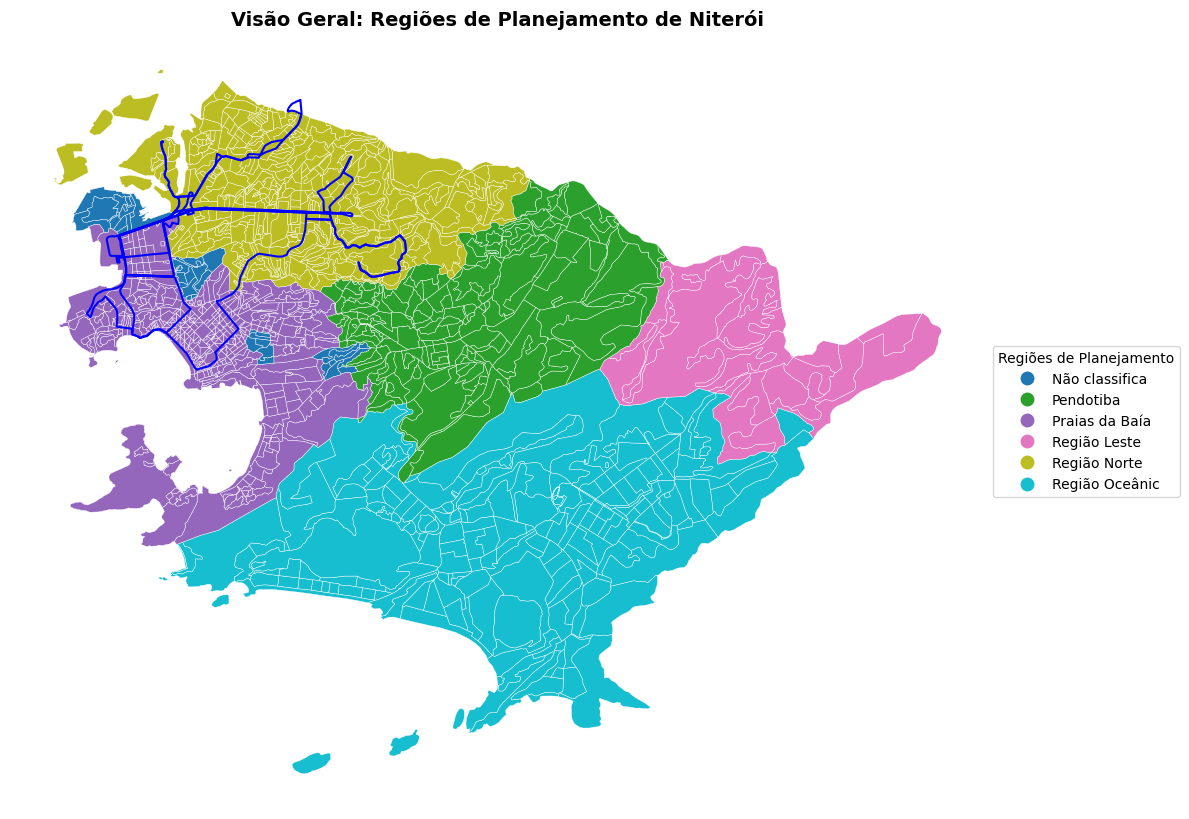

In [21]:
fig, ax = plt.subplots(1, 1, figsize=(12, 12))

setores.plot(
    column="NM_REG_PLAN",
    cmap="tab10", 
    edgecolor="white",
    linewidth=0.3,
    legend=True,
    legend_kwds={
        "title": "Regiões de Planejamento", 
        "loc": "center left", 
        "bbox_to_anchor": (1, 0.5) # Joga a legenda para fora do mapa
    },
    ax=ax
)

rotas_criticas.plot(ax=ax, color='blue', linewidth=1.5, zorder=5)

ax.set_axis_off()
plt.title("Visão Geral: Regiões de Planejamento de Niterói", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

#### Gera um outro dataset somente com as áreas de interesse

In [22]:
filtro=mapa_infraestrutura["NM_REG_PLAN"].isin(["Praias da Baía", "Região Norte"])
mapa_infra_rel=mapa_infraestrutura[filtro]

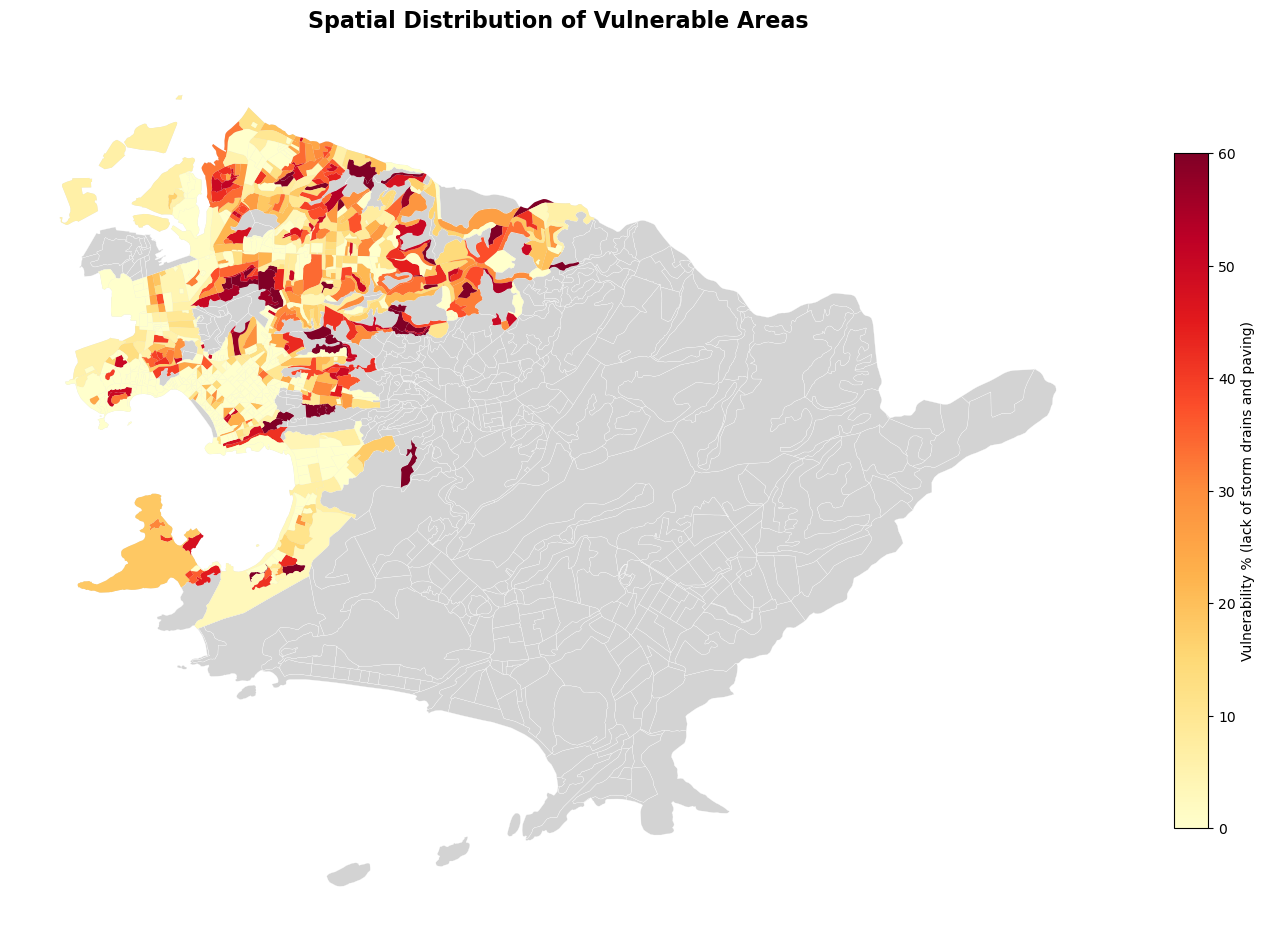

In [53]:
linhas_mais_afetadas = ['41JB','45','OC1','52','61','44'] 


mapas_linhas_onibus = gpd.read_file("line_routes.json")
rotas_criticas = mapa_linhas_onibus[mapa_linhas_onibus['route_short_name'].isin(linhas_mais_afetadas)]
fig, ax = plt.subplots(1, 1, figsize=(14, 10))
setores.plot(ax=ax, color='lightgray', edgecolor='white', linewidth=0.2)

mapa_infra_rel.plot(
    column='indicador_infra', 
    vmax=60,
    cmap='YlOrRd',
    linewidth=0,
    ax=ax,
    legend=True,
    legend_kwds={'label': "Vulnerability % (lack of storm drains and paving)", 'orientation': "vertical", 'shrink': 0.7}
)

#favelas.plot(ax=ax, color='indigo', edgecolor='black', linewidth=0.3)

ax.set_axis_off()
ax.set_title("Spatial Distribution of Vulnerable Areas", fontsize=16, fontweight='bold', pad=20)

# Customizando a legenda para incluir a nova linha
#legenda_favela = mpatches.Patch(color='indigo', label='Favelas')
plt.tight_layout()
plt.savefig("mapa_infra.pdf", bbox_inches='tight', dpi=300)
plt.show()